<a href="https://colab.research.google.com/github/satyapal2240/satya/blob/main/10_Agentic_Digital_Twins_ITS_Book_Chapter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Agentic Digital Twin (ADT) for Intelligent Transportation Systems – Companion Notebook

This notebook accompanies the book chapter *Agentic Digital Twins for Intelligent Transportation Systems: Architecture, Workflows, Applications, and Research Challenges*.

> **Please read first.** Everything here uses a **very small synthetic toy model** of one signalised junction. It is meant to *illustrate ideas* from the chapter: the digital-twin state, an agent, a **policy gateway**, a **fallback**, **staged autonomy**, **ablation** (switching safety rules off one by one) and **evaluation over many random seeds**. It is **not** a validated traffic model. The numbers must **not** be quoted as evidence that ADTs improve real traffic. Real claims need a calibrated simulator (e.g. SUMO), real data, standard baselines and field evidence (chapter Sections 9.5 and 10).

**How to run:** Python 3.9+ with `numpy`, `pandas`, `matplotlib` (Jupyter, VS Code or Google Colab). Run all cells from top to bottom (about 1–3 minutes). All plots are black-and-white.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dataclasses import dataclass, field
from IPython.display import display
plt.style.use("grayscale")
plt.rcParams.update({"figure.dpi":110,"axes.grid":True,"grid.alpha":0.3})
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.4.6 | pandas 2.2.3


## 1. The toy junction (the "physical system")

* Two approaches: **NS** (north–south) and **EW** (east–west). Only one has green at a time.
* Time step = 1 s; one simulated hour (3600 s).
* Vehicles arrive randomly (Poisson). On green, about one vehicle leaves every 2 s (saturation flow 0.5 veh/s).
* Changing phase costs **3 s of lost time** (yellow/all-red) when nobody moves.
* **Demand:** normal at first; NS becomes busy between 1200 s and 2400 s (a "peak"); then normal again.
* **Sensor fault:** the NS detector **freezes** between 1800 s and 2100 s, *during the peak*, so its reading stops updating and its data age grows.
* The controller never sees the true queue, only a **noisy observed queue** (the twin's estimate) and the **age** of each reading.

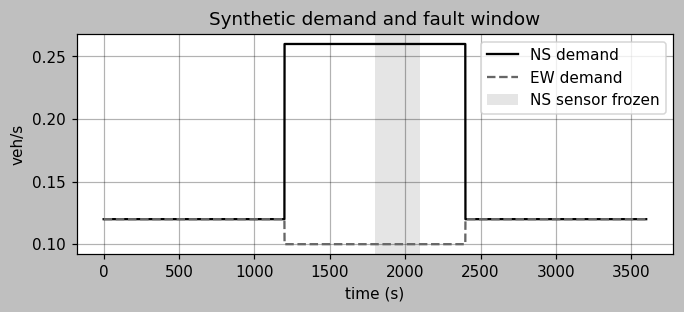

In [2]:
T = 3600
SAT = 0.5            # vehicles per second on green
LOST = 3             # seconds lost when switching phase
MIN_GREEN, MAX_GREEN = 10, 60
STALE_LIMIT = 15     # seconds: older data are not trusted
FAULT = (1800, 2100) # NS detector frozen in this window (inside the peak)

def demand(t):
    """Arrival rates (veh/s) for (NS, EW)."""
    return (0.26, 0.10) if 1200 <= t < 2400 else (0.12, 0.12)

def sensor_fault(t, approach):
    return approach == 0 and FAULT[0] <= t < FAULT[1]

ts = np.arange(T)
plt.figure(figsize=(7,2.6))
plt.plot(ts,[demand(t)[0] for t in ts],label="NS demand"); plt.plot(ts,[demand(t)[1] for t in ts],"--",label="EW demand")
plt.axvspan(*FAULT,alpha=0.2,label="NS sensor frozen"); plt.xlabel("time (s)"); plt.ylabel("veh/s"); plt.legend(); plt.title("Synthetic demand and fault window"); plt.show()

## 2. Controllers

| Controller | Idea | Safety rules |
|---|---|---|
| **Fixed-time** | Repeat a 60 s plan (30 s each way). Ignores data. | Built-in (fixed plan). |
| **Actuated** | A standard baseline: keep green while the current approach still has a queue, switch when it empties (after the minimum green) or when maximum green is reached. Uses the observed queue. **Has no data-fault detection** here. | Min/max green. |
| **Greedy agent** | A one-line "AI proposal": give green to the approach with the longer observed queue. | **None** – can flip every second and trusts any data. |
| **ADT (agent + gateway)** | The same greedy agent, but every proposal passes the **policy gateway**. | Freshness check + fallback, min green, max green, audit log. |

The **policy gateway** (chapter Section 4.4):
1. if data are older than `STALE_LIMIT`, reject the agent and use the **fixed-time fallback**;
2. enforce **minimum green** (no flicker) – also for the fallback;
3. enforce **maximum green** (no starvation of the other approach);
4. write every notable decision to an **audit log**.

*Fairness note:* the greedy agent is a deliberately weak "no safety rules" example. The **actuated** controller is the more meaningful baseline. Real actuated controllers often have detector-fault fail-safes that this toy version leaves out.

In [3]:
@dataclass
class State:
    t: int
    obs: list        # observed queues (twin estimate)
    age: list        # seconds since each sensor last updated
    phase: int       # 0 = NS green, 1 = EW green
    green_t: int     # seconds of green served in the current phase

def fixed_ctrl(s):                       # fixed-time plan, 60 s cycle
    return 0 if (s.t % 60) < 30 else 1

def actuated_ctrl(s):                    # standard-style baseline
    cur, oth = s.phase, 1 - s.phase
    if s.green_t < MIN_GREEN: return cur
    if s.green_t >= MAX_GREEN and s.obs[oth] > 0: return oth
    if s.obs[cur] == 0 and s.obs[oth] > 0: return oth
    return cur

def greedy_agent(s):                     # agent proposal: serve the longer observed queue
    if s.obs[0] == s.obs[1]: return s.phase
    return 0 if s.obs[0] > s.obs[1] else 1

REASONS = ["agent_accepted","fallback_stale","blocked_min_green","forced_max_green"]

class Gateway:
    """Policy gateway around the agent. Flags allow ablation (switching a rule off)."""
    def __init__(self, check_fresh=True, min_green=True, max_green=True):
        self.check_fresh, self.min_green, self.max_green = check_fresh, min_green, max_green
        self.log, self.counts = [], {r:0 for r in REASONS}
    def __call__(self, s):
        prop = greedy_agent(s); oth = 1 - s.phase
        stale = self.check_fresh and max(s.age) > STALE_LIMIT
        cand = fixed_ctrl(s) if stale else prop            # 1. freshness -> fallback
        if self.min_green and cand != s.phase and s.green_t < MIN_GREEN:   # 2. minimum green (also for fallback)
            cmd, reason = s.phase, "blocked_min_green"
            why = f"blocked: min green ({s.green_t}<{MIN_GREEN})"
        elif self.max_green and s.green_t >= MAX_GREEN and (s.obs[oth] > 0 or stale):   # 3. maximum green
            cmd, reason = oth, "forced_max_green"; why = "forced switch: max green reached"
        elif stale:
            cmd, reason = cand, "fallback_stale"; why = f"stale data (age={max(s.age)}s) -> fixed-time fallback"
        else:
            cmd, reason = cand, "agent_accepted"; why = "proposal accepted"
        self.counts[reason] += 1
        if (cmd != prop or stale) and len(self.log) < 30000:   # 4. audit log of notable decisions
            self.log.append((s.t, s.phase, prop, cmd, why))
        return cmd

In [4]:
def simulate(controller, seed, T=T, noise=1, record=False):
    rng = np.random.default_rng(seed)
    q = [0,0]; phase = 0; green_t = 0; lost = 0
    last_obs = [0,0]; age = [0,0]
    qsum = arrivals = departures = switches = maxq = 0
    red_run = [0,0]; max_red = 0; switch_times = []; q_trace = []
    for t in range(T):
        a = rng.poisson(demand(t)); q[0]+=a[0]; q[1]+=a[1]; arrivals += int(a.sum())
        for i in (0,1):                                  # sensing = twin update
            if sensor_fault(t,i): age[i] += 1            # frozen detector: old value, growing age
            else: last_obs[i] = max(0, q[i] + int(rng.integers(-noise, noise+1))); age[i] = 0
        cmd = controller(State(t, list(last_obs), list(age), phase, green_t))
        if lost > 0: lost -= 1
        elif cmd != phase:
            phase = cmd; lost = LOST-1; green_t = 0; switches += 1; switch_times.append(t)
        else:
            green_t += 1
            if q[phase] > 0 and rng.random() < SAT: q[phase] -= 1; departures += 1
        for i in (0,1):                                  # longest wait of a non-empty approach without green
            red_run[i] = 0 if (i == phase and lost == 0) else (red_run[i]+1 if q[i] > 0 else 0)
        max_red = max(max_red, *red_run)
        qsum += q[0]+q[1]; maxq = max(maxq, q[0]+q[1])
        if record: q_trace.append(q[0]+q[1])
    out = {"delay_s_per_veh": qsum/max(arrivals,1), "max_queue": maxq, "switches": switches, "max_red_wait_s": max_red,
           "arrivals": arrivals, "departures": departures, "left_in_queue": q[0]+q[1]}
    if record: out["q_trace"] = np.array(q_trace); out["switch_times"] = switch_times
    return out

show = lambda r: {k: round(float(v),1) for k,v in r.items() if k in ("delay_s_per_veh","max_queue","switches","max_red_wait_s")}
print("Fixed    :", show(simulate(fixed_ctrl, 0)))
print("Actuated :", show(simulate(actuated_ctrl, 0)))
print("Greedy   :", show(simulate(greedy_agent, 0)))
gw = Gateway(); print("ADT      :", show(simulate(gw, 0))); print(gw.counts)

Fixed    : {'delay_s_per_veh': 56.8, 'max_queue': 67.0, 'switches': 119.0, 'max_red_wait_s': 32.0}
Actuated : {'delay_s_per_veh': 12.0, 'max_queue': 17.0, 'switches': 213.0, 'max_red_wait_s': 65.0}
Greedy   : {'delay_s_per_veh': 182.4, 'max_queue': 121.0, 'switches': 608.0, 'max_red_wait_s': 54.0}
ADT      : {'delay_s_per_veh': 17.1, 'max_queue': 23.0, 'switches': 224.0, 'max_red_wait_s': 56.0}
{'agent_accepted': 2461, 'fallback_stale': 285, 'blocked_min_green': 853, 'forced_max_green': 1}


**Delay measure.** Average delay per vehicle is estimated as *total queue-seconds ÷ arrivals* (a Little's-law style estimate). It is a simple proxy, not a field-measured delay. `max_red_wait_s` is the longest time a non-empty approach waited without green (a simple fairness/starvation check; chapter Section 8.2).

## 3. The gateway's audit log

Step 7 of the chapter's loop is *Learn and audit*. Below: the first notable decisions, then decisions inside the sensor-fault window. Each count is **decision-steps** (one decision per second), not distinct events.

In [5]:
gw = Gateway(); simulate(gw, 1)
log = pd.DataFrame(gw.log, columns=["t_s","phase_now","agent_proposal","command","reason"])
print("Decision-step counts:", gw.counts)
display(log.head(8))
print("\nInside the sensor-fault window:")
display(log[(log.t_s>=FAULT[0])&(log.t_s<FAULT[1])&(log.reason.str.contains("stale"))].head(5))

Decision-step counts: {'agent_accepted': 2447, 'fallback_stale': 285, 'blocked_min_green': 863, 'forced_max_green': 5}


,t_s,phase_now,agent_proposal,command,reason
0,0,0,1,0,blocked: min green (0<10)
1,1,0,1,0,blocked: min green (1<10)
2,4,0,1,0,blocked: min green (4<10)
3,7,0,1,0,blocked: min green (7<10)
4,8,0,1,0,blocked: min green (8<10)
5,9,0,1,0,blocked: min green (9<10)
6,28,0,1,0,blocked: min green (2<10)
7,33,0,1,0,blocked: min green (7<10)



Inside the sensor-fault window:


,t_s,phase_now,agent_proposal,command,reason
468,1815,0,0,0,stale data (age=16s) -> fixed-time fallback
469,1816,0,0,0,stale data (age=17s) -> fixed-time fallback
470,1817,0,0,0,stale data (age=18s) -> fixed-time fallback
471,1818,0,0,0,stale data (age=19s) -> fixed-time fallback
472,1819,0,0,0,stale data (age=20s) -> fixed-time fallback


## 4. Comparing controllers over many random seeds

One run proves nothing, so we use **30 seeds** and the **same seeds for every controller** (a *paired* design). We report **mean ± standard deviation**, and for the key question (ADT vs. actuated) a **paired difference with an approximate 95 % interval**.

In [6]:
N = 30; SEEDS = [100+i for i in range(N)]
makers = {"Fixed-time": lambda: fixed_ctrl,
          "Actuated": lambda: actuated_ctrl,
          "Greedy agent (no gateway)": lambda: greedy_agent,
          "ADT (agent + gateway)": lambda: Gateway()}
rows = []
for name, mk in makers.items():
    for sd in SEEDS:
        r = simulate(mk(), sd); r = {k:v for k,v in r.items()}; r["controller"]=name; r["seed"]=sd; rows.append(r)
df = pd.DataFrame(rows)
order = list(makers)
summary = df.groupby("controller").agg(delay_mean=("delay_s_per_veh","mean"), delay_sd=("delay_s_per_veh","std"),
          maxq_mean=("max_queue","mean"), maxq_sd=("max_queue","std"),
          switches=("switches","mean"), max_red_wait=("max_red_wait_s","mean")).loc[order].round(2)
summary

,delay_mean,delay_sd,maxq_mean,maxq_sd,switches,max_red_wait
controller,,,,,,
Fixed-time,56.36,19.62,55.83,16.48,119.00,32.00
Actuated,14.64,7.79,22.53,18.34,207.07,87.70
Greedy agent (no gateway),237.48,63.28,131.00,32.01,593.37,70.13
ADT (agent + gateway),17.10,2.95,25.17,7.37,228.60,54.80


In [7]:
def paired(a, b, col="delay_s_per_veh"):
    x = df[df.controller==a].sort_values("seed")[col].values; y = df[df.controller==b].sort_values("seed")[col].values
    d = x - y; se = d.std(ddof=1)/np.sqrt(len(d)); return d.mean(), d.mean()-1.96*se, d.mean()+1.96*se
for a,b in [("ADT (agent + gateway)","Actuated"),("ADT (agent + gateway)","Fixed-time"),("ADT (agent + gateway)","Greedy agent (no gateway)")]:
    m,lo,hi = paired(a,b); print(f"Delay difference  {a}  minus  {b}: {m:6.1f} s/veh  (approx. 95% interval {lo:.1f} to {hi:.1f})")

Delay difference  ADT (agent + gateway)  minus  Actuated:    2.5 s/veh  (approx. 95% interval -0.6 to 5.5)
Delay difference  ADT (agent + gateway)  minus  Fixed-time:  -39.3 s/veh  (approx. 95% interval -45.8 to -32.7)
Delay difference  ADT (agent + gateway)  minus  Greedy agent (no gateway): -220.4 s/veh  (approx. 95% interval -242.6 to -198.2)


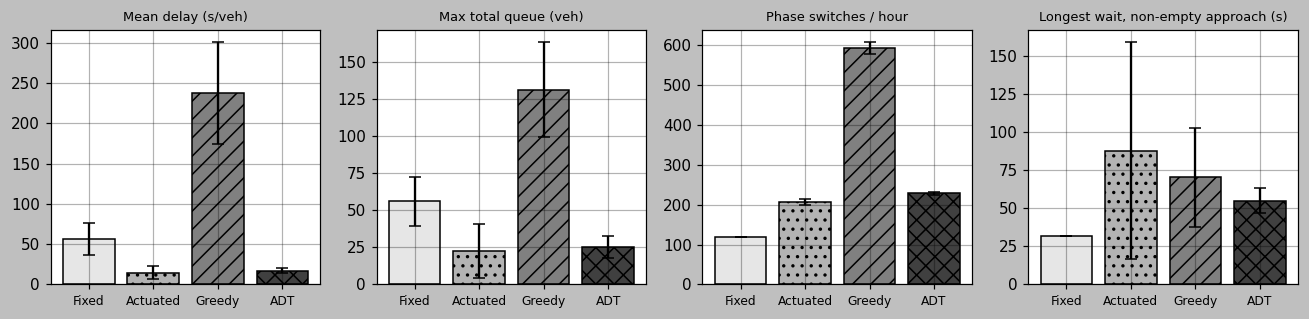

In [8]:
fig, ax = plt.subplots(1,4, figsize=(12,3))
labels = ["Fixed","Actuated","Greedy","ADT"]; hatches = ["", "..", "//", "xx"]
for a, col, ttl in zip(ax, ["delay_s_per_veh","max_queue","switches","max_red_wait_s"],
                       ["Mean delay (s/veh)","Max total queue (veh)","Phase switches / hour","Longest wait, non-empty approach (s)"]):
    m = [df[df.controller==c][col].mean() for c in order]; sd = [df[df.controller==c][col].std() for c in order]
    bars = a.bar(range(4), m, yerr=sd, capsize=4, color=["0.9","0.7","0.5","0.25"], edgecolor="k")
    for b,h in zip(bars,hatches): b.set_hatch(h)
    a.set_xticks(range(4)); a.set_xticklabels(labels, fontsize=8); a.set_title(ttl, fontsize=8.5)
plt.tight_layout(); plt.show()

**How to read this – and what NOT to conclude.**
* The **greedy agent** has no safety rules and flips phase constantly, so it wastes time in lost time. Its poor result shows the value of safety limits, *not* that AI control is bad.
* **Fixed-time** struggles in the NS peak because a 30/30 split cannot adapt.
* The meaningful comparison is **ADT vs. actuated**. In the saved run the two are **close on mean delay** (the paired interval above includes or nearly includes zero), while the ADT shows **less run-to-run spread** and a **shorter worst-case wait** for a non-empty approach. So the gateway here buys *predictability and bounded behaviour*, not a large average gain. Any difference is specific to this toy scenario, noise level and fault; a well-tuned real adaptive system could do better or worse.
* A good result on delay is not enough: also look at switches (flicker) and the longest wait (starvation). The gateway's purpose is to keep an agent's good ideas **bounded and safe**.
* Real conclusions need real data, validated simulation, standard baselines and field evidence (chapter Sections 9.5 and 10).

## 5. Ablation: what does each gateway rule do?

We switch off **one rule at a time** and compare with the full gateway (same 30 paired seeds). If a rule matters, removing it should make something worse. The *freshness check* is most visible because the fault lands in the peak.

In [9]:
abl = {"Full gateway": dict(), "No freshness check": dict(check_fresh=False),
       "No minimum green": dict(min_green=False), "No maximum green": dict(max_green=False)}
rows=[]
for name, kw in abl.items():
    for sd in SEEDS:
        r = simulate(Gateway(**kw), sd); r["variant"]=name; r["seed"]=sd; rows.append(r)
ab = pd.DataFrame(rows)
ab_tab = ab.groupby("variant").agg(delay_mean=("delay_s_per_veh","mean"), delay_sd=("delay_s_per_veh","std"),
          maxq_mean=("max_queue","mean"), switches=("switches","mean"), max_red_wait=("max_red_wait_s","mean")).loc[list(abl)].round(2)
ab_tab

,delay_mean,delay_sd,maxq_mean,switches,max_red_wait
variant,,,,,
Full gateway,17.10,2.95,25.17,228.60,54.80
No freshness check,16.21,6.36,23.27,234.23,61.70
No minimum green,150.40,48.93,91.83,554.33,62.47
No maximum green,17.18,3.05,25.13,228.70,60.87


Read the table row by row. In the saved run:
* **No minimum green** is by far the most damaging change: many more switches (flicker) and much higher delay.
* **No freshness check** did *not* raise the average delay here; its main visible effect is a larger **spread between runs** (compare `delay_sd`). The fallback gives up a little average performance for more predictable behaviour when data cannot be trusted. The frozen reading in this toy is a fairly mild fault.
* **No maximum green** changed almost nothing, because the agent switches often enough that maximum green is rarely reached.

A rule that shows little effect in this toy scenario is **not** proven unnecessary: it only means this scenario did not stress it. Try the experiments in Section 9 (for example a harsher fault or a lopsided demand) to stress it.

## 6. One run over time (the fault window is shaded)

The curves are a trailing 30 s average of the total queue (one seed).

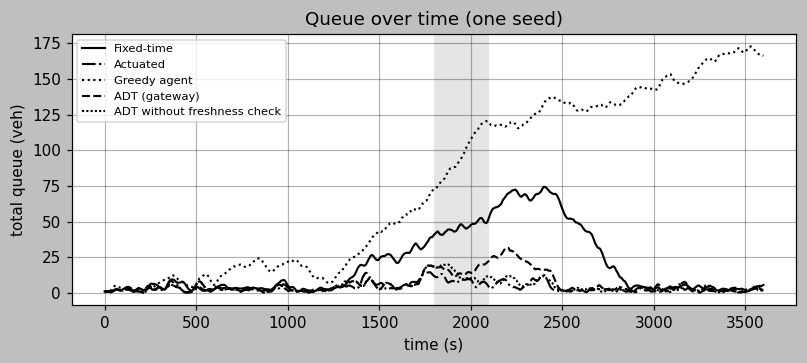

In [10]:
plt.figure(figsize=(8.5,3.2))
for lab, ctrl, ls in [("Fixed-time", fixed_ctrl, "-"), ("Actuated", actuated_ctrl, "-."), ("Greedy agent", greedy_agent, ":"), ("ADT (gateway)", Gateway(), "--"),
                      ("ADT without freshness check", Gateway(check_fresh=False), (0,(1,1)))]:
    y = pd.Series(simulate(ctrl, 7, record=True)["q_trace"]).rolling(30, min_periods=1).mean()
    plt.plot(y.values, ls=ls, color="k", lw=1.4, label=lab)
plt.axvspan(*FAULT, alpha=0.2); plt.xlabel("time (s)"); plt.ylabel("total queue (veh)"); plt.legend(fontsize=7.5); plt.title("Queue over time (one seed)"); plt.show()

## 7. Staged autonomy (chapter Section 8.1)

The chapter recommends moving gradually. We imitate the stages with the same agent and the **same paired seeds**. A hard **interlock** (minimum green) is applied to every command in every stage, as real signal hardware would do.

| Stage | What reaches the "road" |
|---|---|
| Stage 0 – Fixed plan only (reference) | Fixed-time plan. No agent. |
| Stage 1 – Shadow | Fixed-time plan applies. The ADT recommendation is **only logged**. |
| Stage 2 – Advisory | Every 10 s an operator accepts the recommendation with probability 0.8; otherwise the fixed plan stays. |
| Stage 3 – Bounded automation | The ADT command (with gateway) applies directly. |

`agreement` = share of seconds in which the command applied to the road equals the ADT recommendation. In shadow mode a low agreement is a *signal to investigate* before moving on (gate criteria, chapter Table 8).

In [11]:
def interlock(s, cmd):                       # hard-wired minimum green for every stage
    return s.phase if (cmd != s.phase and s.green_t < MIN_GREEN) else cmd

def make_stage(stage, seed):
    gw = Gateway(); rng = np.random.default_rng(seed+999); st = {"agree":0,"n":0,"accept":True}
    def ctrl(s):
        rec = gw(s); fx = fixed_ctrl(s)
        if stage == "fixed":      cmd = fx
        elif stage == "shadow":   cmd = fx
        elif stage == "advisory":
            if s.t % 10 == 0: st["accept"] = rng.random() < 0.8
            cmd = interlock(s, rec if st["accept"] else fx)
        else:                     cmd = rec
        st["n"] += 1; st["agree"] += int(cmd == rec); return cmd
    return ctrl, st

rows=[]
for stage in ["fixed","shadow","advisory","bounded"]:
    for sd in SEEDS:
        ctrl, st = make_stage(stage, sd); r = simulate(ctrl, sd); r["stage"]=stage; r["seed"]=sd; r["agreement"]=st["agree"]/st["n"]; rows.append(r)
sdf = pd.DataFrame(rows)
stage_tab = sdf.groupby("stage").agg(delay_mean=("delay_s_per_veh","mean"), delay_sd=("delay_s_per_veh","std"),
            switches=("switches","mean"), max_red_wait=("max_red_wait_s","mean"), agreement=("agreement","mean")).loc[["fixed","shadow","advisory","bounded"]].round(2)
stage_tab

,delay_mean,delay_sd,switches,max_red_wait,agreement
stage,,,,,
fixed,56.36,19.62,119.0,32.00,0.66
shadow,56.36,19.62,119.0,32.00,0.66
advisory,19.88,3.75,218.6,59.37,0.96
bounded,17.10,2.95,228.6,54.80,1.00


**Reading the table.** *Fixed* and *shadow* give the **same road performance** (nothing from the agent is applied in shadow mode), which is why they must match when seeds are paired – the only difference is that shadow mode also measures agreement. *Advisory* mixes the operator's choices with the fixed plan. *Bounded* applies the ADT command directly. The point is the **procedure**: measure at each stage, then decide whether the gate criteria are met.

## 8. Self-checks (the code tests its own safety rules)

These checks fail loudly (`AssertionError`) if the simulator or the gateway breaks a rule. They are the notebook equivalent of the chapter's call for repeatable tests and "no unauthorised commands" before moving to a pilot.

In [12]:
bad = 0
for sd in SEEDS[:10]:
    # (a) conservation: every arrival either departed or is still queued
    r = simulate(fixed_ctrl, sd); assert r["arrivals"] == r["departures"] + r["left_in_queue"], "vehicle conservation broken"
    # (b) full gateway never switches faster than MIN_GREEN + LOST
    g = Gateway(); r = simulate(g, sd, record=True); st = r["switch_times"]
    gaps = np.diff(st) if len(st) > 1 else np.array([MIN_GREEN+LOST])
    assert gaps.min() >= MIN_GREEN + LOST, f"gateway allowed a switch after only {gaps.min()} s"
    # (c) during the fault the gateway really used the fallback
    assert g.counts["fallback_stale"] > 0, "freshness check never triggered"
    # (d) ablation sanity: with min-green off the agent is allowed to switch faster
    r2 = simulate(Gateway(min_green=False), sd, record=True); gaps2 = np.diff(r2["switch_times"])
    bad += int(gaps2.min() < MIN_GREEN + LOST)
assert bad > 0, "min-green ablation never produced a fast switch (check the model)"
# (e) shadow stage equals fixed plan on the same seeds
a = sdf[sdf.stage=="fixed"].sort_values("seed").delay_s_per_veh.values; b = sdf[sdf.stage=="shadow"].sort_values("seed").delay_s_per_veh.values
assert np.allclose(a, b), "shadow mode should not change road performance"
print("All self-checks passed.")

All self-checks passed.
